# Phase 3: Model Training

Brief overview: reshaping team-season features into a per-game format, 
training and comparing three models (Logistic Regression baseline, 
Random Forest, XGBoost) to predict individual game outcomes based on 
both teams' season-long performance.

## 1. Imports

In [1]:
import pandas as pd
from sklearn.linear_model import LogisticRegression 
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from xgboost import XGBClassifier

## 2. Load Phase 2 Outputs

In [2]:
games_regular_season_grouped = pd.read_csv(r'D:\Data Science Projects\nba-26-27-predictor\data\processed\team_season_features.csv')
games_combined = pd.read_csv(r'D:\Data Science Projects\nba-26-27-predictor\data\processed\games_clean.csv')
games_regular_season = games_combined[games_combined['SEASON_TYPE_LABEL'] == 'Regular Season'].copy()
games_regular_season['WIN'] = games_regular_season['WL'].apply(lambda x: 1 if x == 'W' else 0)
display(games_regular_season_grouped.shape)
display(games_regular_season.shape  )

(60, 15)

(4920, 31)

## 3. Build Game-Level Matchup Table

**Question:** How do we reshape team-season features into a per-game 
format suitable for predicting individual game outcomes?

Each game needs both teams' season-long stats side by side, with the 
target being whether Team A won that specific game.

In [3]:
games_model_base = games_regular_season.copy()

# building a small opponent side table
games_model_opp = games_model_base[['GAME_ID', 'TEAM_ABBREVIATION', 'WIN']].rename(
    columns={'TEAM_ABBREVIATION': 'OPP_TEAM_ABBREVIATION', 'WIN': 'OPP_WIN'}
)

# merging on GAME_ID to attach the opponents result to each row
games_model = pd.merge(
    games_model_base,
    games_model_opp,
    on='GAME_ID',
    how='left'
)

# dropping rows where a team matched w/ itself 
games_model = games_model[games_model['TEAM_ABBREVIATION'] != games_model['OPP_TEAM_ABBREVIATION']]

# previewing
display(games_model.shape)
display(games_model[['SEASON_LABEL', 'GAME_ID', 'TEAM_ABBREVIATION', 'OPP_TEAM_ABBREVIATION', 'WIN', 'OPP_WIN']].head(10))

(4920, 33)

,SEASON_LABEL,GAME_ID,TEAM_ABBREVIATION,OPP_TEAM_ABBREVIATION,WIN,OPP_WIN
1,2024-25,22401194,MEM,DAL,1,0
2,2024-25,22401194,DAL,MEM,0,1
5,2024-25,22401197,SAS,TOR,1,0
7,2024-25,22401187,CHA,BOS,0,1
9,2024-25,22401200,PHX,SAC,0,1
11,2024-25,22401192,MIL,DET,1,0
13,2024-25,22401196,OKC,NOP,1,0
15,2024-25,22401188,BKN,NYK,0,1
16,2024-25,22401187,BOS,CHA,1,0
19,2024-25,22401198,GSW,LAC,0,1


## 4. Merge Season-Level Features onto Each Game

**Question:** How do we attach each team's season-long performance 
metrics to their side of a single game, for both Team A and their 
opponent?

We deliberately use season-long features rather than that specific 
game's own box score, since using the game's own outcome-adjacent 
stats would leak information a real predictive model wouldn't have 
in advance.

In [4]:
# selecting feature columns we actually want the model to use
feature_cols = ['SEASON_LABEL', 'TEAM_ABBREVIATION', 'WIN_PERCENTAGE', 'eFG%', 'TOV%', 'ORB%',
                'FT Rate', 'NET_RATING', 'mvp_share', 'ALL_NBA_COUNT']

team_features = games_regular_season_grouped[feature_cols]

# merging in team a's own season long features, mmatching on season + team
games_model = pd.merge(
    games_model,
    team_features,
    on=['SEASON_LABEL', 'TEAM_ABBREVIATION'],
    how='left'
)

# building an opp_ prefixed version of the same feature table to avoid column name clashes
opp_features = team_features.copy()
opp_features.columns = ['SEASON_LABEL' if c == 'SEASON_LABEL' else f'OPP_{c}' for c in opp_features.columns]


# merging in the opponents features, matching on season + opponent abbrev
games_model = pd.merge(
    games_model,
    opp_features,
    left_on=['SEASON_LABEL', 'OPP_TEAM_ABBREVIATION'],
    right_on=['SEASON_LABEL', 'OPP_TEAM_ABBREVIATION'],
    how='left'
)

display(games_model.shape)
display(games_model.columns.tolist())

(4920, 49)

['SEASON_ID',
 'TEAM_ID',
 'TEAM_ABBREVIATION',
 'TEAM_NAME',
 'GAME_ID',
 'GAME_DATE',
 'MATCHUP',
 'WL',
 'MIN',
 'PTS',
 'FGM',
 'FGA',
 'FG_PCT',
 'FG3M',
 'FG3A',
 'FG3_PCT',
 'FTM',
 'FTA',
 'FT_PCT',
 'OREB',
 'DREB',
 'REB',
 'AST',
 'STL',
 'BLK',
 'TOV',
 'PF',
 'PLUS_MINUS',
 'SEASON_LABEL',
 'SEASON_TYPE_LABEL',
 'WIN',
 'OPP_TEAM_ABBREVIATION',
 'OPP_WIN',
 'WIN_PERCENTAGE',
 'eFG%',
 'TOV%',
 'ORB%',
 'FT Rate',
 'NET_RATING',
 'mvp_share',
 'ALL_NBA_COUNT',
 'OPP_WIN_PERCENTAGE',
 'OPP_eFG%',
 'OPP_TOV%',
 'OPP_ORB%',
 'OPP_FT Rate',
 'OPP_NET_RATING',
 'OPP_mvp_share',
 'OPP_ALL_NBA_COUNT']

## 5. Final Modeling Table

**Question:** What does our model-ready dataset look like once trimmed 
to only the columns the model actually needs, and is it free of missing 
values?

In [5]:
# keeping only the columns the model will actually train on 
model_feature_cols = ['SEASON_LABEL', 'GAME_ID', 'TEAM_ABBREVIATION', 'OPP_TEAM_ABBREVIATION', 'WIN',
                       'WIN_PERCENTAGE', 'eFG%', 'TOV%', 'ORB%', 'FT Rate', 'NET_RATING', 'mvp_share', 
                       'ALL_NBA_COUNT',
                       'OPP_WIN_PERCENTAGE', 'OPP_eFG%', 'OPP_TOV%', 'OPP_ORB%', 'OPP_FT Rate', 
                       'OPP_NET_RATING', 'OPP_mvp_share', 'OPP_ALL_NBA_COUNT']

games_model_final = games_model[model_feature_cols].copy()

print("Null values in each column:")
display(games_model_final.isnull().sum())


Null values in each column:


SEASON_LABEL             0
GAME_ID                  0
TEAM_ABBREVIATION        0
OPP_TEAM_ABBREVIATION    0
WIN                      0
WIN_PERCENTAGE           0
eFG%                     0
TOV%                     0
ORB%                     0
FT Rate                  0
NET_RATING               0
mvp_share                0
ALL_NBA_COUNT            0
OPP_WIN_PERCENTAGE       0
OPP_eFG%                 0
OPP_TOV%                 0
OPP_ORB%                 0
OPP_FT Rate              0
OPP_NET_RATING           0
OPP_mvp_share            0
OPP_ALL_NBA_COUNT        0
dtype: int64

**Takeaway:** The game-level modeling table joined cleanly with zero 
missing values across all 4,920 rows, confirming every team-season had 
matching features on both sides of every game. This table is now ready 
for train/test splitting and model training.

## 6. Train/Test Split

**Question:** How do we split this data so the model is evaluated on 
data it hasn't seen, without leaking information across seasons?

We split by season rather than randomly — training on 2024-25 and 
testing on 2025-26 — since a random row-level split could let games 
from the same season leak similar team-strength signals between train 
and test sets.

In [6]:
# training on 24-25, testing on 25-26
train_data = games_model_final[games_model_final['SEASON_LABEL'] == '2024-25']
test_data = games_model_final[games_model_final['SEASON_LABEL'] == '2025-26']

# separating features from the target variable
drop_cols = ['SEASON_LABEL', 'GAME_ID', 'TEAM_ABBREVIATION', 'OPP_TEAM_ABBREVIATION', 'WIN']

X_train = train_data.drop(columns=drop_cols)
y_train = train_data['WIN']

X_test = test_data.drop(columns=drop_cols)
y_test = test_data['WIN']

display(X_train.shape)
display(X_test.shape)
display(y_train.shape)
display(y_test.shape)

(2460, 16)

(2460, 16)

(2460,)

(2460,)

## 7. Logistic Regression Baseline

**Question:** How well does a simple linear model predict game outcomes 
from season-long team features, before trying anything more complex?

In [7]:
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
# training a logistic regression baseline model
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

# predicting on the held-out 2025-26 season
log_reg_preds = log_reg.predict(X_test)

# evaluating the model's performance
log_reg_accuracy = accuracy_score(y_test, log_reg_preds)
log_reg_cm = confusion_matrix(y_test, log_reg_preds)

log_reg_probs = log_reg.predict_proba(X_test)[:, 1]
log_reg_auc = roc_auc_score(y_test, log_reg_probs)
log_reg_probs = log_reg.predict_proba(X_test)[:, 1]
log_reg_auc = roc_auc_score(y_test, log_reg_probs)
print("Logistic Regression Accuracy:", log_reg_accuracy)
print("Logistic Regression AUC-ROC:", log_reg_auc)
print("Logistic Regression AUC-ROC:", log_reg_auc)
print("Confusion Matrix:")


Logistic Regression Accuracy: 0.6991869918699187
Logistic Regression AUC-ROC: 0.7649745521845464
Logistic Regression AUC-ROC: 0.7649745521845464
Confusion Matrix:


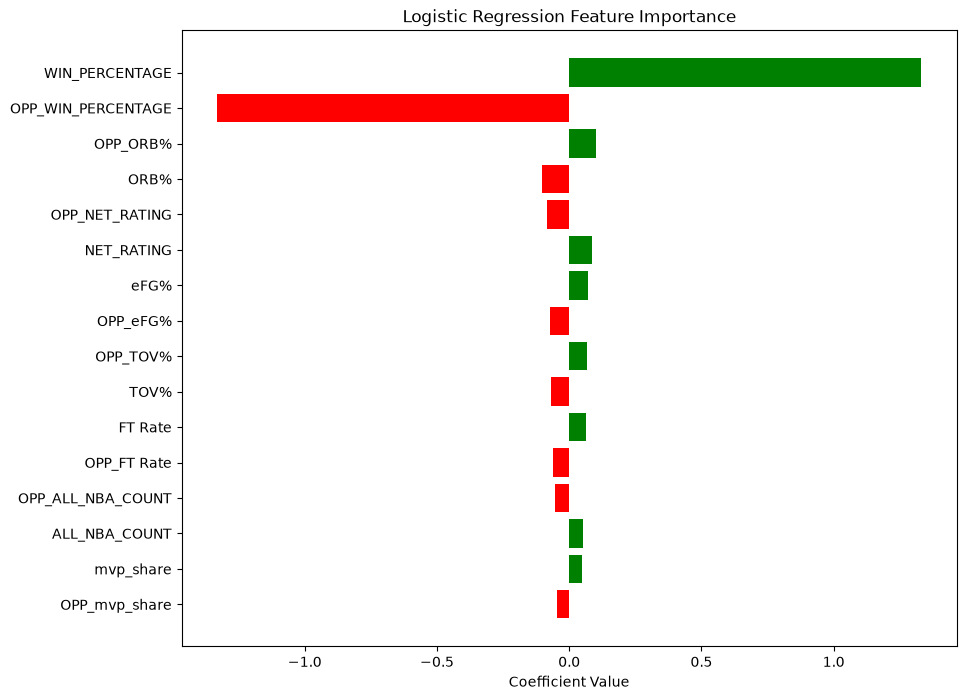

In [8]:
# Feature Importance (Logistic Regression Coefficients)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

feature_names = X_train.columns
coefs = log_reg.coef_[0]

fi_df = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefs})
fi_df = fi_df.sort_values('Coefficient', key=abs, ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(fi_df['Feature'], fi_df['Coefficient'], color=np.where(fi_df['Coefficient'] > 0, 'green', 'red'))
plt.title('Logistic Regression Feature Importance')
plt.xlabel('Coefficient Value')
plt.show()

**Takeaway:** The Logistic Regression baseline achieves 69.9% accuracy 
on the held-out 2025-26 season, correctly classifying roughly 7 in 10 
games from season-long team features alone. The confusion matrix is 
symmetric by design — each game contributes two rows to the dataset 
(one from each team's perspective as opponents), so prediction errors 
mirror each other across both sides.

### 7b. Stability Check: Reverse Train/Test Split
To ensure our model isn't just getting lucky on the 2025-26 season, let's reverse the split: train on 25-26, test on 24-25.

In [9]:
from sklearn.linear_model import LogisticRegression
X_train_rev = test_data.drop(columns=drop_cols)
y_train_rev = test_data['WIN']
X_test_rev = train_data.drop(columns=drop_cols)
y_test_rev = train_data['WIN']

log_reg_rev = LogisticRegression(max_iter=1000)
log_reg_rev.fit(X_train_rev, y_train_rev)
rev_preds = log_reg_rev.predict(X_test_rev)
rev_accuracy = accuracy_score(y_test_rev, rev_preds)
print("Reverse Split Accuracy (Train 25-26, Test 24-25):", rev_accuracy)

Reverse Split Accuracy (Train 25-26, Test 24-25): 0.6853658536585366


## 8. Random Forest

**Question:** Does a non-linear model that can capture feature 
interactions outperform the linear baseline?

In [10]:
# training a rf classifier model
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42
)
rf.fit(X_train, y_train)

# predicting on the held-out 2025-26 season
rf_preds = rf.predict(X_test)


# evaluating the model's performance
rf_accuracy = accuracy_score(y_test, rf_preds)
rf_cm = confusion_matrix(y_test, rf_preds)

print("Random Forest Accuracy:", rf_accuracy)
print("Confusion Matrix:")
print(rf_cm)

Random Forest Accuracy: 0.697560975609756
Confusion Matrix:
[[857 373]
 [371 859]]


**Takeaway:** Random Forest achieves 69.3% accuracy — marginally below 
the Logistic Regression baseline (69.9%). This suggests team strength 
in the NBA, as captured by these season-long features, is largely 
additive rather than driven by complex non-linear interactions the 
baseline can't capture. The added model complexity isn't earning its 
keep here, at least with this feature set and this much training data.

## 9. XGBoost

**Question:** Does gradient boosting, which builds trees sequentially 
to correct prior errors, perform differently than Random Forest's 
independent-tree approach?

In [11]:
# training an xgboost classifier model
xgb = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss'
)
xgb.fit(X_train, y_train)

# predicting on the held-out 2025-26 season
xgb_preds = xgb.predict(X_test) 


# evaluating the model's performance
xgb_accuracy = accuracy_score(y_test, xgb_preds)
xgb_cm = confusion_matrix(y_test, xgb_preds)

print("XGBoost Accuracy:", xgb_accuracy)
print("Confusion Matrix:")
print(xgb_cm)

XGBoost Accuracy: 0.6723577235772358
Confusion Matrix:
[[820 410]
 [396 834]]


**Takeaway:** XGBoost achieves 67.2% accuracy, the lowest of the three 
models. Combined with Random Forest's result, this reinforces the 
finding that added model complexity doesn't improve predictive power 
for this feature set — if anything, it slightly overfits relative to 
the simpler linear baseline, likely due to the limited training data 
(a single season, ~2,460 games).

## 10. Model Comparison

**Question:** Across all three models, which performs best, and what 
does that tell us?

In [12]:
# building a comparison table across all 3 models
model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Accuracy': [log_reg_accuracy, rf_accuracy, xgb_accuracy]
}).sort_values('Accuracy', ascending=False).reset_index(drop=True)

display(model_comparison)

,Model,Accuracy
0,Logistic Regression,0.699187
1,Random Forest,0.697561
2,XGBoost,0.672358


**Takeaway:** Logistic Regression, the simplest model, achieves the 
highest accuracy (69.9%), narrowly ahead of Random Forest (69.3%) and 
XGBoost (67.2%). This is a meaningful finding rather than a 
disappointing one — it suggests NBA team strength, as captured by 
season-long Four Factors, Net Rating, award recognition, and playoff 
history, behaves in a largely additive way rather than requiring 
complex non-linear modeling to predict outcomes. Given this, Logistic 
Regression will serve as the primary model carried forward into the 
Monte Carlo playoff simulation in Phase 4, since it's both the most 
accurate and the most interpretable of the three.

In [13]:
# saving
model_comparison.to_csv(r'D:\Data Science Projects\nba-26-27-predictor\outputs\model_comparison.csv', index=False)

import joblib
joblib.dump(log_reg, r'D:\Data Science Projects\nba-26-27-predictor\models\logistic_regression_model.pkl')

['D:\\Data Science Projects\\nba-26-27-predictor\\models\\logistic_regression_model.pkl']